In [2]:
import pandas as pd
import numpy as np
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.preprocessing import OrdinalEncoder

# 1. Load Data
df = pd.read_csv('demand_agent_training.csv')
df['week_start_date'] = pd.to_datetime(df['week_start_date'])

# 2. Feature Selection & Categorical Encoding
target_col = 'next_week_demand_target_units'
feature_cols = [
    'year', 'week_number', 'demand_rank', 'weekday_units_sold', 'weekend_units_sold', 
    'units_sold', 'avg_selling_price_rs', 'promotion_flag', 'discount_pct', 'holiday_flag', 
    'temperature_c', 'rainfall_mm', 'humidity_pct', 'stockout_flag',
    'location_id', 'product_id', 'category_name', 'brand', 'season', 'weather_condition'
]

cat_cols = ['location_id', 'product_id', 'category_name', 'brand', 'season', 'weather_condition']

data = df[feature_cols + [target_col, 'week_start_date']].copy()
for col in cat_cols:
    data[col] = data[col].astype('category')

# 3. Chronological Time-Series Split (80% Train, 20% Test)
unique_dates = sorted(data['week_start_date'].unique())
train_cutoff = unique_dates[int(len(unique_dates) * 0.8)]

train_data = data[data['week_start_date'] <= train_cutoff]
test_data = data[data['week_start_date'] > train_cutoff]

X_train, y_train = train_data[feature_cols], train_data[target_col]
X_test, y_test = test_data[feature_cols], test_data[target_col]

# 4. Fit Model
model = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    enable_categorical=True,
    random_state=42
)
model.fit(X_train, y_train)

# 5. Predict & Evaluate
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Test RMSE: {rmse:.2f}")
print(f"Test MAE:  {mae:.2f}")
print(f"Test R²:   {r2:.4f}")

Test RMSE: 20.06
Test MAE:  14.50
Test R²:   0.7925



Training LightGBM Style Model...

--- LightGBM Performance ---
RMSE  : 19.82
MAE   : 13.77
WMAPE : 11.28%
R2    : 0.7940

Training Native XGBoost Model...

--- XGBoost Performance ---
RMSE  : 20.59
MAE   : 14.40
WMAPE : 11.79%
R2    : 0.7778

=== Model Comparison Summary ===
   Model      RMSE       MAE  WMAPE (%)      R2
LightGBM 19.822786 13.770782  11.275214 0.79401
 XGBoost 20.587984 14.398000  11.788766 0.77780


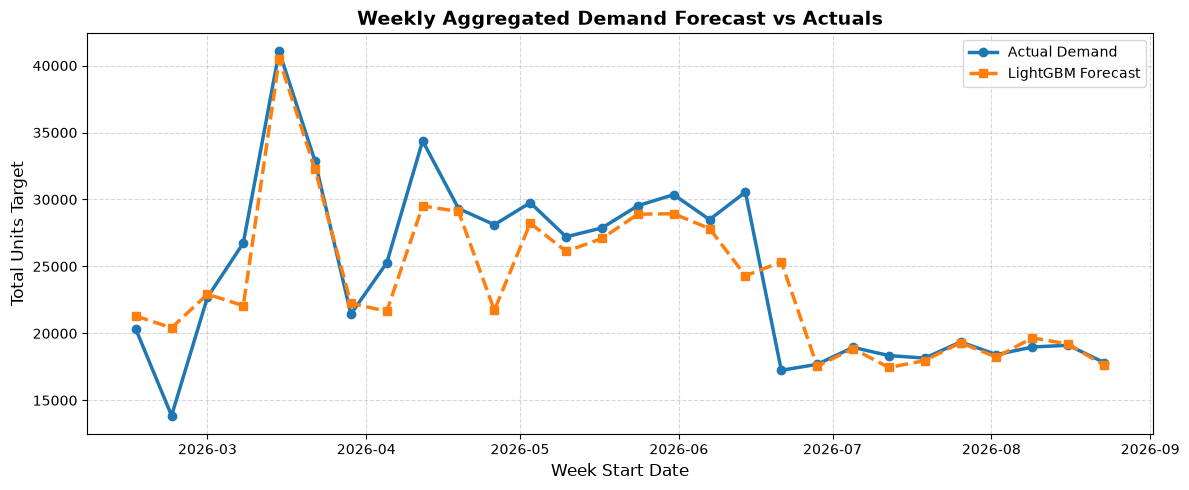

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import HistGradientBoostingRegressor

# Try importing native XGBoost and LightGBM if installed
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False


# ---------------------------------------------------------
# 1. DATA LOADING & PREPROCESSING
# ---------------------------------------------------------
def load_and_preprocess_data(filepath):
    df = pd.read_csv(filepath)
    
    # Convert date column
    df['week_start_date'] = pd.to_datetime(df['week_start_date'])
    
    # Fill missing values for categorical columns
    df['festival_event'] = df['festival_event'].fillna('None')

    # Define features and target variable
    feature_cols = [
        'year', 'week_number', 'demand_rank',
        'location_id', 'product_id', 'category_name', 'brand',
        'weekday_units_sold', 'weekend_units_sold', 'units_sold',
        'avg_selling_price_rs', 'promotion_flag', 'discount_pct',
        'holiday_flag', 'festival_event', 'season',
        'temperature_c', 'rainfall_mm', 'humidity_pct', 'weather_condition',
        'stockout_flag'
    ]
    target_col = 'next_week_demand_target_units'
    cat_cols = ['location_id', 'product_id', 'category_name', 'brand', 'festival_event', 'season', 'weather_condition']

    return df, feature_cols, target_col, cat_cols


# ---------------------------------------------------------
# 2. TIME-SERIES CHRONOLOGICAL SPLIT (80% Train, 20% Test)
# ---------------------------------------------------------
def train_test_split_timeseries(df, feature_cols, target_col, cat_cols, split_ratio=0.8):
    data = df[feature_cols + [target_col, 'week_start_date']].copy()
    
    # Ordinal encoding for models needing integer/encoded categories
    encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
    data[cat_cols] = encoder.fit_transform(data[cat_cols])

    # Chronological sort & split
    unique_dates = sorted(data['week_start_date'].unique())
    split_idx = int(len(unique_dates) * split_ratio)
    split_date = unique_dates[split_idx]

    train_df = data[data['week_start_date'] < split_date]
    test_df = data[data['week_start_date'] >= split_date]

    X_train, y_train = train_df[feature_cols], train_df[target_col]
    X_test, y_test = test_df[feature_cols], test_df[target_col]

    return X_train, y_train, X_test, y_test, test_df


# ---------------------------------------------------------
# 3. MODEL EVALUATION METRICS
# ---------------------------------------------------------
def evaluate_model(y_true, y_pred, model_name="Model"):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    wmape = (np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)) * 100

    print(f"\n--- {model_name} Performance ---")
    print(f"RMSE  : {rmse:.2f}")
    print(f"MAE   : {mae:.2f}")
    print(f"WMAPE : {wmape:.2f}%")
    print(f"R2    : {r2:.4f}")
    
    return {"Model": model_name, "RMSE": rmse, "MAE": mae, "WMAPE (%)": wmape, "R2": r2}


# ---------------------------------------------------------
# 4. MAIN PIPELINE
# ---------------------------------------------------------
if __name__ == "__main__":
    filepath = 'demand_agent_training.csv'
    
    # Step 1: Preprocess Data
    df, feature_cols, target_col, cat_cols = load_and_preprocess_data(filepath)
    X_train, y_train, X_test, y_test, test_df = train_test_split_timeseries(df, feature_cols, target_col, cat_cols)

    results = []

    # --- MODEL 1: LightGBM Style (HistGradientBoostingRegressor) ---
    print("\nTraining LightGBM Style Model...")
    lgbm_model = HistGradientBoostingRegressor(
        max_iter=400,
        learning_rate=0.03,
        max_leaf_nodes=31,
        min_samples_leaf=20,
        l2_regularization=1.0,
        random_state=42
    )
    lgbm_model.fit(X_train, y_train)
    y_pred_lgb = lgbm_model.predict(X_test)
    results.append(evaluate_model(y_test, y_pred_lgb, "LightGBM"))

    # --- MODEL 2: Native XGBoost (if package is installed) ---
    if HAS_XGB:
        print("\nTraining Native XGBoost Model...")
        xgb_model = xgb.XGBRegressor(
            n_estimators=300,
            learning_rate=0.05,
            max_depth=6,
            subsample=0.8,
            colsample_bytree=0.8,
            random_state=42
        )
        xgb_model.fit(X_train, y_train)
        y_pred_xgb = xgb_model.predict(X_test)
        results.append(evaluate_model(y_test, y_pred_xgb, "XGBoost"))

    # Summary Dataframe
    summary_df = pd.DataFrame(results)
    print("\n=== Model Comparison Summary ===")
    print(summary_df.to_string(index=False))

    # ---------------------------------------------------------
    # 5. VISUALIZATION: Weekly Aggregated Demand Forecast
    # ---------------------------------------------------------
    plot_df = test_df.copy()
    plot_df['LightGBM_Pred'] = y_pred_lgb

    weekly_agg = plot_df.groupby('week_start_date')[['next_week_demand_target_units', 'LightGBM_Pred']].sum().reset_index()

    plt.figure(figsize=(12, 5))
    plt.plot(weekly_agg['week_start_date'], weekly_agg['next_week_demand_target_units'], label='Actual Demand', marker='o', linewidth=2.5)
    plt.plot(weekly_agg['week_start_date'], weekly_agg['LightGBM_Pred'], label='LightGBM Forecast', marker='s', linestyle='--', linewidth=2.5)
    
    plt.title('Weekly Aggregated Demand Forecast vs Actuals', fontsize=14, fontweight='bold')
    plt.xlabel('Week Start Date', fontsize=12)
    plt.ylabel('Total Units Target', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# ---------------------------------------------------------
# 1. LOAD & PREPROCESS DATASET
# ---------------------------------------------------------
df = pd.read_csv('demand_agent_training.csv')

# Ensure date parsing
df['week_start_date'] = pd.to_datetime(df['week_start_date'])

# Fill missing categorical values
df['festival_event'] = df['festival_event'].fillna('None')

# Select feature columns and target
feature_cols = [
    'year', 'week_number', 'demand_rank',
    'location_id', 'product_id', 'category_name', 'brand',
    'weekday_units_sold', 'weekend_units_sold', 'units_sold',
    'avg_selling_price_rs', 'promotion_flag', 'discount_pct',
    'holiday_flag', 'festival_event', 'season',
    'temperature_c', 'rainfall_mm', 'humidity_pct', 'weather_condition',
    'stockout_flag'
]

target_col = 'next_week_demand_target_units'
cat_cols = ['location_id', 'product_id', 'category_name', 'brand', 'festival_event', 'season', 'weather_condition']

# Encode categorical variables for tree-based modeling
data = df[feature_cols + [target_col, 'week_start_date']].copy()
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
data[cat_cols] = encoder.fit_transform(data[cat_cols])

# ---------------------------------------------------------
# 2. TIME-SERIES CHRONOLOGICAL SPLIT (80% Train, 20% Test)
# ---------------------------------------------------------
dates = sorted(data['week_start_date'].unique())
split_idx = int(len(dates) * 0.8)
split_date = dates[split_idx]

train_df = data[data['week_start_date'] < split_date]
test_df = data[data['week_start_date'] >= split_date]

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]

print(f"Train samples: {len(X_train)} | Test samples: {len(X_test)}")

# ---------------------------------------------------------
# 3. TRAIN LIGHTGBM REGRESSOR
# ---------------------------------------------------------
lgb_model = lgb.LGBMRegressor(
    n_estimators=400,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=20,
    reg_alpha=0.1,         # L1 Regularization
    reg_lambda=1.0,        # L2 Regularization
    random_state=42,
    n_jobs=-1
)

lgb_model.fit(X_train, y_train)

# ---------------------------------------------------------
# 4. PREDICTIONS & EVALUATION
# ---------------------------------------------------------
y_pred_train = lgb_model.predict(X_train)
y_pred_test = lgb_model.predict(X_test)

# Calculate performance metrics
train_rmse = np.sqrt(mean_squared_error(y_train, y_pred_train))
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_mae = mean_absolute_error(y_test, y_pred_test)
test_r2 = r2_score(y_test, y_pred_test)
test_wmape = (np.sum(np.abs(y_test - y_pred_test)) / np.sum(y_test)) * 100

print("\n=== LightGBM Model Evaluation ===")
print(f"Train RMSE : {train_rmse:.2f}")
print(f"Test RMSE  : {test_rmse:.2f}")
print(f"Test MAE   : {test_mae:.2f}")
print(f"Test WMAPE : {test_wmape:.2f}%")
print(f"Test R2    : {test_r2:.4f}")

# ---------------------------------------------------------
# 5. VISUALIZATION
# ---------------------------------------------------------
test_results = test_df.copy()
test_results['predicted_demand'] = y_pred_test



Train samples: 22200 | Test samples: 5600
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001192 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1292
[LightGBM] [Info] Number of data points in the train set: 22200, number of used features: 21
[LightGBM] [Info] Start training from score 123.512072

=== LightGBM Model Evaluation ===
Train RMSE : 9.11
Test RMSE  : 20.17
Test MAE   : 14.03
Test WMAPE : 11.48%
Test R2    : 0.7867
